In [16]:
from pathlib import Path
import hashlib, json, platform, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Robust project root: works when launched from either the project root or notebooks/.
HERE = Path.cwd()
ROOT = HERE.parent if HERE.name == "notebooks" else HERE
DATA_PATH = ROOT / "data" / "synthetic_daily_demand_demo.csv"
RESULTS_DIR = ROOT / "results"
FIGURES_DIR = ROOT / "figures"
for folder in (RESULTS_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

SEED = 2026
ORIGINS = [360, 420, 480, 540, 600, 660]
HORIZON = 30
SHIFT_INDEX = 480
GREEN = "#16803c"
PINK = "#ec168c"
DARK_GREEN = "#006b2d"
GRAY = "#777777"
plt.rcParams.update({"font.size": 9, "axes.titlesize": 12, "axes.labelsize": 10,
                     "legend.fontsize": 8, "figure.dpi": 110})
print("Project root:", ROOT.resolve())
print("Python:", sys.version.split()[0], "| pandas:", pd.__version__,
      "| scikit-learn:", sklearn.__version__)
print("Frozen protocol:", len(ORIGINS), "rolling origins,", HORIZON, "days per origin")

Project root: C:\Users\allde\Downloads\DS_A5_Time_Series_Rolling_Evaluation_Code_Only_Clean_Outputs_Package\DS_A5_Time_Series_Rolling_Evaluation
Python: 3.12.7 | pandas: 2.2.2 | scikit-learn: 1.5.1
Frozen protocol: 6 rolling origins, 30 days per origin


In [17]:
if not DATA_PATH.exists():
    rng = np.random.default_rng(SEED)
    n = 720
    dates_gen = pd.date_range("2024-01-01", periods=n, freq="D")
    t = np.arange(n)
    weekly = 12 * np.sin(2 * np.pi * t / 7)
    longer_cycle = 18 * np.sin(2 * np.pi * t / 180)
    trend = 0.025 * t
    shift = np.where(t >= SHIFT_INDEX, 18.0, 0.0)
    noise_scale = np.where(t >= SHIFT_INDEX, 7.5, 3.5)
    y_gen = 100 + weekly + longer_cycle + trend + shift + rng.normal(0, noise_scale)
    pd.DataFrame({"date": dates_gen, "demand_units": y_gen}).to_csv(
        DATA_PATH, index=False, float_format="%.6f"
    )

raw = pd.read_csv(DATA_PATH, parse_dates=["date"])
sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert {"date", "demand_units"}.issubset(raw.columns)
assert raw["date"].is_monotonic_increasing and raw["date"].is_unique
assert raw["demand_units"].notna().all()
assert len(raw) == 720, f"Expected 720 rows in the frozen demo, got {len(raw)}"
dates = raw["date"].to_numpy()
series = raw["demand_units"].to_numpy(dtype=float)

provenance = pd.DataFrame([{
    "dataset": DATA_PATH.name,
    "data_type": "synthetic demonstration; not real-world evidence",
    "rows": len(raw),
    "date_start": raw["date"].min().date().isoformat(),
    "date_end": raw["date"].max().date().isoformat(),
    "sha256": sha256,
    "seed": SEED,
}])
display(provenance)
provenance.to_csv(RESULTS_DIR / "data_provenance.csv", index=False)
display(raw.head())
display(raw.describe(include="all").T)

,dataset,data_type,rows,date_start,date_end,sha256,seed
0,synthetic_daily_demand_demo.csv,synthetic demonstration; not real-world evidence,720,2024-01-01,2025-12-20,dcfbc7cc577864da600cecd328795a1291d95fdf541c65...,2026


,date,demand_units
0,2024-01-01,97.224071
1,2024-01-02,110.877168
2,2024-01-03,106.367609
3,2024-01-04,112.048318
4,2024-01-05,99.632543


,count,mean,min,25%,50%,75%,max,std
date,720,2024-12-25 12:00:00,2024-01-01 00:00:00,2024-06-28 18:00:00,2024-12-25 12:00:00,2025-06-23 06:00:00,2025-12-20 00:00:00,NaN
demand_units,720.0,115.143138,67.658285,101.059408,114.247608,128.196223,167.853035,19.285211


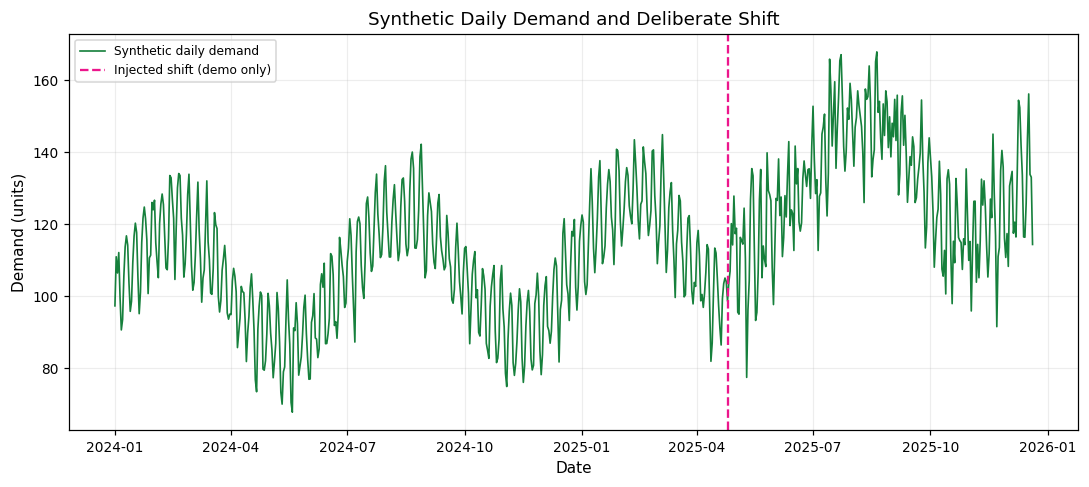

In [18]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(raw["date"], series, color=GREEN, lw=1.1, label="Synthetic daily demand")
ax.axvline(pd.Timestamp(dates[SHIFT_INDEX]), color=PINK, ls="--", lw=1.5,
           label="Injected shift (demo only)")
ax.set(title="Synthetic Daily Demand and Deliberate Shift",
       xlabel="Date", ylabel="Demand (units)")
ax.legend()
ax.grid(alpha=.22)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_demo_series_and_shift.png", dpi=220, bbox_inches="tight")
plt.show()

In [19]:
def features_at(indices):
    rows = []
    for i in indices:
        if i < 14:
            raise ValueError("Feature index must be at least 14.")
        rows.append({
            "lag_1": series[i - 1],
            "lag_2": series[i - 2],
            "lag_7": series[i - 7],
            "lag_14": series[i - 14],
            "rolling_mean_7": series[i - 7:i].mean(),
            "rolling_std_7": series[i - 7:i].std(ddof=1),
            "day_of_week": pd.Timestamp(dates[i]).dayofweek,
        })
    return pd.DataFrame(rows, index=indices)

feature_example = features_at(np.array([14, 15, 16]))
display(feature_example)
assert feature_example.index.min() >= 14
print("Leakage rule: all lag/rolling predictors end before the target timestamp.")

,lag_1,lag_2,lag_7,lag_14,rolling_mean_7,rolling_std_7,day_of_week
14,98.534535,95.697677,105.593018,97.224071,106.839088,8.177370,0
15,109.363695,98.534535,113.606639,110.877168,107.377756,8.205751,1
16,116.607913,109.363695,116.695760,106.367609,107.806510,8.651744,2


Leakage rule: all lag/rolling predictors end before the target timestamp.


In [20]:
metric_rows, prediction_rows = [], []
fold_predictions = []
for fold, origin in enumerate(ORIGINS, start=1):
    test_idx = np.arange(origin, min(origin + HORIZON, len(series)))
    train_idx = np.arange(14, origin)
    assert len(test_idx) == HORIZON, "A rolling test window is shorter than the declared horizon."
    assert train_idx.max() < test_idx.min(), "Temporal leakage: training targets overlap the test window."

    X_train, X_test = features_at(train_idx), features_at(test_idx)
    y_train, y_test = series[train_idx], series[test_idx]

    ridge_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=10.0)),
    ])
    ridge_pipeline.fit(X_train, y_train)

    predictions = {
        "Persistence": series[test_idx - 1],
        "Seasonal naive (7d)": series[test_idx - 7],
        "Ridge lag model": ridge_pipeline.predict(X_test),
    }
    fold_predictions.append((fold, origin, test_idx, y_test, predictions))

    for j, idx in enumerate(test_idx):
        row = {
            "fold": fold,
            "origin_index": int(origin),
            "origin_date": str(pd.Timestamp(dates[origin]).date()),
            "target_index": int(idx),
            "target_date": str(pd.Timestamp(dates[idx]).date()),
            "actual": float(y_test[j]),
        }
        for name, pred_values in predictions.items():
            key = {"Persistence": "persistence",
                   "Seasonal naive (7d)": "seasonal_naive_7",
                   "Ridge lag model": "ridge_lag_model"}[name]
            row[key] = float(pred_values[j])
        prediction_rows.append(row)

    for name, pred_values in predictions.items():
        metric_rows.append({
            "fold": fold,
            "origin_index": int(origin),
            "origin_date": str(pd.Timestamp(dates[origin]).date()),
            "test_start": str(pd.Timestamp(dates[test_idx[0]]).date()),
            "test_end": str(pd.Timestamp(dates[test_idx[-1]]).date()),
            "n_train": len(train_idx),
            "n_test": len(test_idx),
            "model": name,
            "MAE": mean_absolute_error(y_test, pred_values),
            "RMSE": mean_squared_error(y_test, pred_values) ** 0.5,
        })

metrics = pd.DataFrame(metric_rows)
predictions = pd.DataFrame(prediction_rows)
metrics.to_csv(RESULTS_DIR / "demo_rolling_metrics.csv", index=False)
predictions.to_csv(RESULTS_DIR / "demo_rolling_predictions.csv", index=False)
print("Rolling evaluation complete:", len(ORIGINS), "folds;",
      len(predictions), "timestamp-level predictions.")
display(metrics.round(3))

Rolling evaluation complete: 6 folds; 180 timestamp-level predictions.


,fold,origin_index,origin_date,test_start,test_end,n_train,n_test,model,MAE,RMSE
0,1,360,2024-12-26,2024-12-26,2025-01-24,346,30,Persistence,8.046,9.243
1,1,360,2024-12-26,2024-12-26,2025-01-24,346,30,Seasonal naive (7d),5.129,6.258
2,1,360,2024-12-26,2024-12-26,2025-01-24,346,30,Ridge lag model,4.243,5.214
3,2,420,2025-02-24,2025-02-24,2025-03-25,406,30,Persistence,8.742,9.862
4,2,420,2025-02-24,2025-02-24,2025-03-25,406,30,Seasonal naive (7d),5.086,6.284
5,2,420,2025-02-24,2025-02-24,2025-03-25,406,30,Ridge lag model,4.753,5.547
6,3,480,2025-04-25,2025-04-25,2025-05-24,466,30,Persistence,11.591,14.598
7,3,480,2025-04-25,2025-04-25,2025-05-24,466,30,Seasonal naive (7d),10.563,13.226
8,3,480,2025-04-25,2025-04-25,2025-05-24,466,30,Ridge lag model,8.847,10.872
9,4,540,2025-06-24,2025-06-24,2025-07-23,526,30,Persistence,10.203,12.444


,model,mean_MAE,sd_MAE,mean_RMSE,sd_RMSE
1,Ridge lag model,6.592,1.833,8.167,2.368
2,Seasonal naive (7d),8.145,2.555,10.186,3.317
0,Persistence,9.760,1.273,11.546,1.954


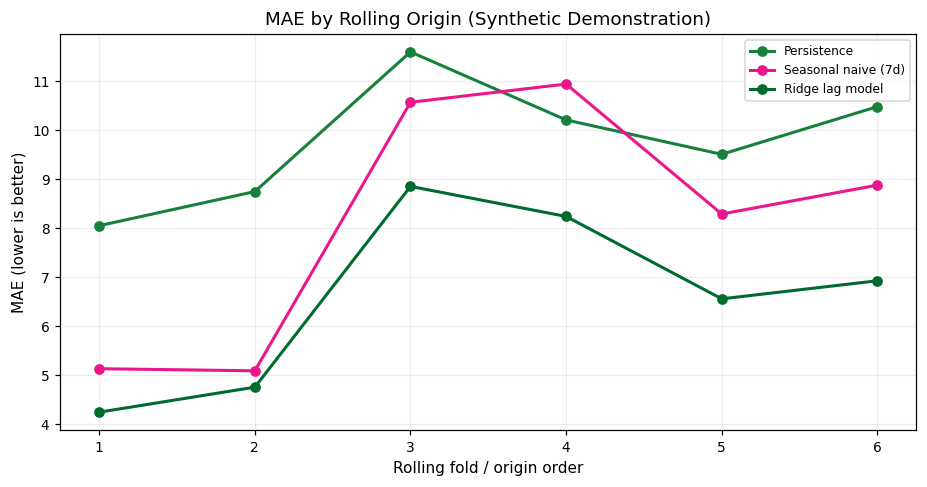

In [21]:
summary = (metrics.groupby("model", as_index=False)
           .agg(mean_MAE=("MAE", "mean"), sd_MAE=("MAE", "std"),
                mean_RMSE=("RMSE", "mean"), sd_RMSE=("RMSE", "std")))
summary = summary.sort_values("mean_MAE")
display(summary.round(3))
summary.to_csv(RESULTS_DIR / "demo_model_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(8.5, 4.5))
for name, color in [("Persistence", GREEN),
                    ("Seasonal naive (7d)", PINK),
                    ("Ridge lag model", DARK_GREEN)]:
    s = metrics[metrics["model"] == name]
    ax.plot(s["fold"], s["MAE"], marker="o", lw=2, color=color, label=name)
ax.set(title="MAE by Rolling Origin (Synthetic Demonstration)",
       xlabel="Rolling fold / origin order", ylabel="MAE (lower is better)")
ax.set_xticks(ORIGINS and range(1, len(ORIGINS) + 1))
ax.legend()
ax.grid(alpha=.22)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_demo_mae_by_origin.png", dpi=220, bbox_inches="tight")
plt.show()

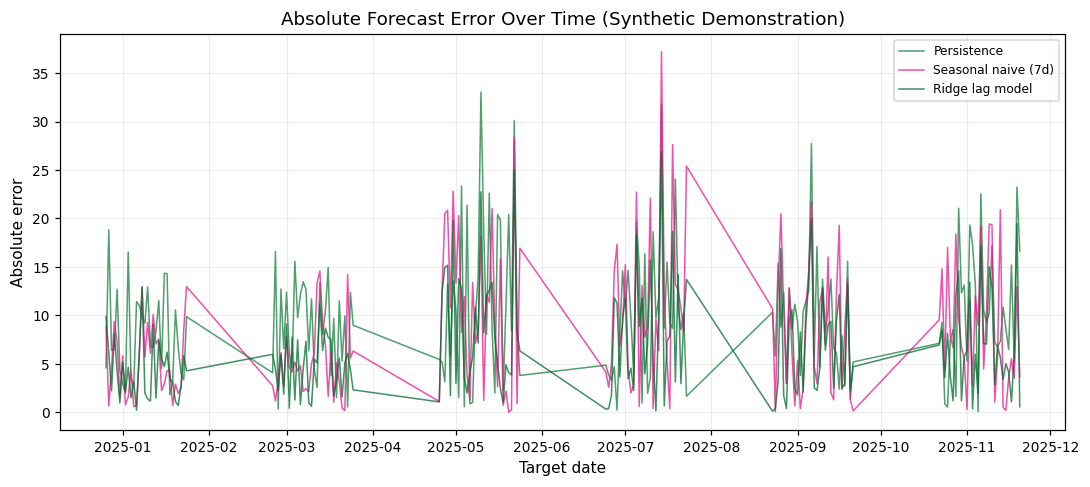

In [22]:
pred_sorted = predictions.sort_values(["target_date", "fold"]).copy()
pred_sorted["target_date"] = pd.to_datetime(pred_sorted["target_date"])
fig, ax = plt.subplots(figsize=(10, 4.5))
for key, name, color in [
    ("persistence", "Persistence", GREEN),
    ("seasonal_naive_7", "Seasonal naive (7d)", PINK),
    ("ridge_lag_model", "Ridge lag model", DARK_GREEN),
]:
    ax.plot(pred_sorted["target_date"],
            np.abs(pred_sorted["actual"] - pred_sorted[key]),
            color=color, lw=1, alpha=.75, label=name)
ax.set(title="Absolute Forecast Error Over Time (Synthetic Demonstration)",
       xlabel="Target date", ylabel="Absolute error")
ax.legend()
ax.grid(alpha=.22)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_demo_error_over_time.png", dpi=220, bbox_inches="tight")
plt.show()

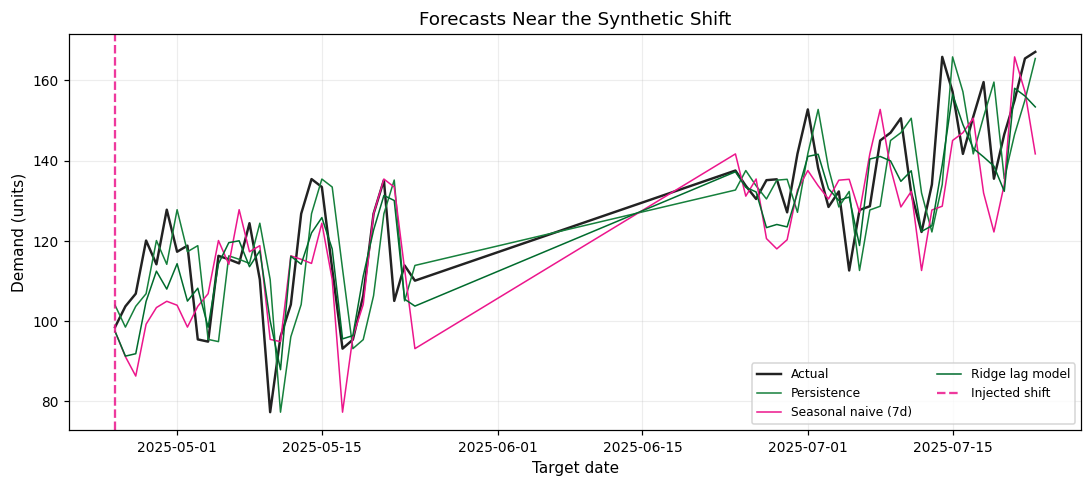

In [23]:
sample = pred_sorted[
    (pred_sorted["target_date"] >= pd.Timestamp(dates[450])) &
    (pred_sorted["target_date"] <= pd.Timestamp(dates[570]))
].copy()
sample = sample.drop_duplicates(subset=["target_date"], keep="last")
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(sample["target_date"], sample["actual"], color="#222222", lw=1.6, label="Actual")
for key, name, color in [
    ("persistence", "Persistence", GREEN),
    ("seasonal_naive_7", "Seasonal naive (7d)", PINK),
    ("ridge_lag_model", "Ridge lag model", DARK_GREEN),
]:
    ax.plot(sample["target_date"], sample[key], color=color, lw=1, label=name)
ax.axvline(pd.Timestamp(dates[SHIFT_INDEX]), color=PINK, ls="--",
           alpha=.85, label="Injected shift")
ax.set(title="Forecasts Near the Synthetic Shift",
       xlabel="Target date", ylabel="Demand (units)")
ax.legend(ncol=2)
ax.grid(alpha=.22)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_demo_predictions_near_shift.png", dpi=220, bbox_inches="tight")
plt.show()

,period,n,mean_abs_error,median_abs_error
0,After shift,120,7.640,6.369
1,Before shift,60,4.498,4.467


C:\Users\allde\AppData\Local\Temp\ipykernel_22828\3625859430.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([


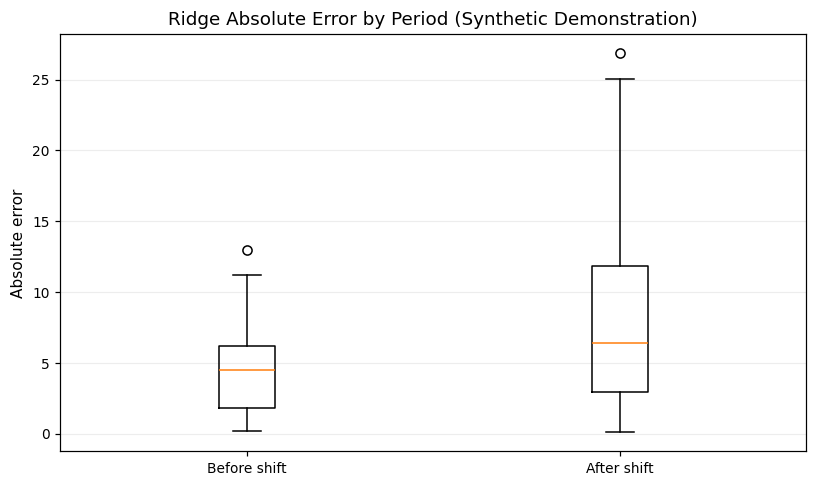

In [24]:
ridge_errors = pred_sorted.copy()
ridge_errors["ridge_abs_error"] = np.abs(ridge_errors["actual"] - ridge_errors["ridge_lag_model"])
ridge_errors["period"] = np.where(
    ridge_errors["target_date"] < pd.Timestamp(dates[SHIFT_INDEX]),
    "Before shift", "After shift"
)
period_summary = (ridge_errors.groupby("period", as_index=False)
                  .agg(n=("ridge_abs_error", "size"),
                       mean_abs_error=("ridge_abs_error", "mean"),
                       median_abs_error=("ridge_abs_error", "median")))
display(period_summary.round(3))
period_summary.to_csv(RESULTS_DIR / "demo_shift_error_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.boxplot([
    ridge_errors.loc[ridge_errors["period"] == "Before shift", "ridge_abs_error"],
    ridge_errors.loc[ridge_errors["period"] == "After shift", "ridge_abs_error"],
], labels=["Before shift", "After shift"])
ax.set(title="Ridge Absolute Error by Period (Synthetic Demonstration)",
       ylabel="Absolute error")
ax.grid(axis="y", alpha=.22)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_demo_error_shift_comparison.png", dpi=220, bbox_inches="tight")
plt.show()

In [25]:
fold_table = metrics.pivot(index="fold", columns="model", values="MAE").reset_index()
fold_table["Ridge_minus_persistence_MAE"] = (
    fold_table["Ridge lag model"] - fold_table["Persistence"]
)
display(fold_table.round(3))
fold_table.to_csv(RESULTS_DIR / "demo_fold_diagnostics.csv", index=False)

print("Interpretation prompts:")
print("1. Does the model ranking stay the same at every origin?")
print("2. Does the higher-noise/shift period coincide with worse errors for every model?")
print("3. Could overlapping test windows or seasonal composition partly explain the apparent change?")

model,fold,Persistence,Ridge lag model,Seasonal naive (7d),Ridge_minus_persistence_MAE
0,1,8.046,4.243,5.129,-3.804
1,2,8.742,4.753,5.086,-3.989
2,3,11.591,8.847,10.563,-2.744
3,4,10.203,8.235,10.935,-1.968
4,5,9.502,6.554,8.284,-2.948
5,6,10.474,6.923,8.874,-3.552


Interpretation prompts:
1. Does the model ranking stay the same at every origin?
2. Does the higher-noise/shift period coincide with worse errors for every model?
3. Could overlapping test windows or seasonal composition partly explain the apparent change?


In [26]:
leakage_checks = pd.DataFrame([
    ["Training targets precede test targets", "PASS", "Asserted for every rolling origin"],
    ["Features stop at t-1", "PASS", "Lag and rolling features exclude the target day"],
    ["Preprocessing refit inside each fold", "PASS", "Imputer and scaler are inside the fold-specific pipeline"],
    ["At least five rolling origins", "PASS", f"{len(ORIGINS)} origins declared"],
    ["Real-world feature publication delays", "NOT VERIFIED", "Synthetic demo has no real publication pipeline"],
    ["Real operational target availability", "NOT VERIFIED", "Must be documented for the assessed dataset"],
], columns=["Check", "Status", "Evidence / limitation"])
display(leakage_checks)
leakage_checks.to_csv(RESULTS_DIR / "demo_leakage_audit.csv", index=False)

,Check,Status,Evidence / limitation
0,Training targets precede test targets,PASS,Asserted for every rolling origin
1,Features stop at t-1,PASS,Lag and rolling features exclude the target day
2,Preprocessing refit inside each fold,PASS,Imputer and scaler are inside the fold-specifi...
3,At least five rolling origins,PASS,6 origins declared
4,Real-world feature publication delays,NOT VERIFIED,Synthetic demo has no real publication pipeline
5,Real operational target availability,NOT VERIFIED,Must be documented for the assessed dataset


In [27]:
availability_path = ROOT / "templates" / "feature_availability_map_template.csv"
if availability_path.exists():
    availability_map = pd.read_csv(availability_path)
    display(availability_map)
else:
    availability_map = pd.DataFrame(columns=[
        "field", "meaning", "event_timestamp", "available_timestamp",
        "publication_delay", "available_at_origin", "evidence_or_source"
    ])
    display(availability_map)
print("Template location:", availability_path)

,field,meaning,true_availability_time,available_at_forecast_origin,assumption_or_risk
0,date,calendar timestamp,At forecast origin,Yes,Index/time key only; not a future outcome
1,demand_units (target),Observed demand value,After measurement/reporting for that day,"No, except past lags",Target at t is unavailable before its observat...
2,lag_1,demand at t-1,After t-1 value is reported,"Yes, if reporting delay permits",Verify actual reporting latency in real applic...
3,lag_7,demand at t-7,After t-7 value is reported,"Yes, if reported by origin",Past-only lag
4,rolling_mean_7,Mean demand from t-7..t-1,After all values in the window are reported,"Yes, if all are available",Right endpoint excludes t
5,day_of_week,Calendar-derived feature,Known from calendar,Yes,"Known future covariate, if date is known"


Template location: C:\Users\allde\Downloads\DS_A5_Time_Series_Rolling_Evaluation_Code_Only_Clean_Outputs_Package\DS_A5_Time_Series_Rolling_Evaluation\templates\feature_availability_map_template.csv


In [28]:
critical_period_record = pd.DataFrame([{
    "demo_rule": "Injected change begins at index 480 by construction",
    "demo_start_date": str(pd.Timestamp(dates[SHIFT_INDEX]).date()),
    "interpretation": "Teaching example only; not a detected real-world drift event",
    "real_task_rule_TODO": "Predeclare a rule tied to the actual operational context",
}])
display(critical_period_record)
critical_period_record.to_csv(RESULTS_DIR / "critical_period_record_demo.csv", index=False)

,demo_rule,demo_start_date,interpretation,real_task_rule_TODO
0,Injected change begins at index 480 by constru...,2025-04-25,Teaching example only; not a detected real-wor...,Predeclare a rule tied to the actual operation...


In [29]:
monitoring_plan = pd.DataFrame([
    ["Data freshness", "Check feature timestamps and ingestion delay", "Block prediction if required inputs are stale"],
    ["Forecast error", "Track MAE/RMSE once labels arrive; require minimum sample size", "Investigate sustained deterioration against baseline"],
    ["Drift signal", "Use a predeclared feature/target distribution statistic", "Treat as a trigger to investigate, not proof of causal drift"],
    ["Retraining", "Retrain only after a defined evidence threshold and validation", "Compare candidate against the frozen baseline before release"],
    ["Fallback", "Keep a simple baseline and define an operational owner", "Revert to baseline or manual process if data/model checks fail"],
], columns=["Area", "Monitoring rule to specify", "Fallback / response"])
display(monitoring_plan)
monitoring_plan.to_csv(RESULTS_DIR / "monitoring_fallback_scaffold.csv", index=False)

,Area,Monitoring rule to specify,Fallback / response
0,Data freshness,Check feature timestamps and ingestion delay,Block prediction if required inputs are stale
1,Forecast error,Track MAE/RMSE once labels arrive; require min...,Investigate sustained deterioration against ba...
2,Drift signal,Use a predeclared feature/target distribution ...,"Treat as a trigger to investigate, not proof o..."
3,Retraining,Retrain only after a defined evidence threshol...,Compare candidate against the frozen baseline ...
4,Fallback,Keep a simple baseline and define an operation...,Revert to baseline or manual process if data/m...


In [30]:
environment = {
    "purpose": "synthetic worked example only; not a completed assessed submission",
    "python": sys.version,
    "platform": platform.platform(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
    "seed": SEED,
    "rolling_origins": ORIGINS,
    "horizon_days": HORIZON,
    "dataset_sha256": sha256,
    "feature_rule": "lags/rolling windows end at t-1",
    "preprocessing": "median imputation and standard scaling fit inside each fold",
}
(RESULTS_DIR / "demo_environment.json").write_text(json.dumps(environment, indent=2), encoding="utf-8")
print(json.dumps(environment, indent=2))
print("\nFigures:")
for p in sorted(FIGURES_DIR.glob("*.png")):
    print(" -", p.name, f"({p.stat().st_size:,} bytes)")
print("\nResult files:")
for p in sorted(RESULTS_DIR.iterdir()):
    print(" -", p.name)

{
  "purpose": "synthetic worked example only; not a completed assessed submission",
  "python": "3.12.7 | packaged by Anaconda, Inc. | (main, Oct  4 2024, 13:17:27) [MSC v.1929 64 bit (AMD64)]",
  "platform": "Windows-11-10.0.26300-SP0",
  "numpy": "1.26.4",
  "pandas": "2.2.2",
  "scikit_learn": "1.5.1",
  "seed": 2026,
  "rolling_origins": [
    360,
    420,
    480,
    540,
    600,
    660
  ],
  "horizon_days": 30,
  "dataset_sha256": "dcfbc7cc577864da600cecd328795a1291d95fdf541c657ec2efcbfcb92e8250",
  "feature_rule": "lags/rolling windows end at t-1",
  "preprocessing": "median imputation and standard scaling fit inside each fold"
}

Figures:
 - 01_demo_series_and_shift.png (276,328 bytes)
 - 02_demo_mae_by_origin.png (144,537 bytes)
 - 03_demo_error_over_time.png (400,963 bytes)
 - 04_demo_predictions_near_shift.png (301,984 bytes)
 - 05_demo_error_shift_comparison.png (47,900 bytes)

Result files:
 - critical_period_record_demo.csv
 - data_provenance.csv
 - demo_environment